<div style="background-color:#B5121B;color:#ffffff;padding:16px 22px;border-radius:6px;font-family:Arial, Helvetica, sans-serif;">
<div style="font-size:12px;letter-spacing:0.08em;text-transform:uppercase;opacity:0.85;">PHYS7101 &middot; Numerical Methods and Data Analysis</div>
<div style="font-size:21px;font-weight:700;margin-top:6px;line-height:1.3;">Exercise 1: The large-amplitude pendulum</div>
</div>

#### Exemplar solution
***

This is a full model answer to Exercise 1. It shows everything the brief asked for and more: **you did not need all
of this for an A.** Read it alongside your own notebook and your feedback. It is most useful for *how* each result is
reached and checked, and for how each result leads to the next question.

It follows the brief's advice: a Markdown cell before each block of code (what and why) and one after it (what the
result shows). Each "what it shows" cell answers the **Report** line for that task.

**What was going on.** The data were simulated, and the true model contained **quadratic (air) drag** as well as the linear damping the
brief asked you to fit. A linear-damping-only model *cannot* fit these data perfectly. The skill being assessed was
noticing that, from the evidence, rather than reporting the 30σ-off value of $g$ as the answer. Task 6 shows one way to find
the cause.


## Setup
Load the record, convert to radians, and set the constants from the brief. The local value of $g$ is computed here from a
published formula, so the source is in the notebook: the WGS84 normal-gravity (Somigliana) formula at Lancaster's latitude
(54.0° N), minus the free-air correction for about 50 m height.
**Source:** NIMA TR8350.2, *Department of Defense World Geodetic System 1984*, 3rd ed. (2000), eq. 4-1; free-air gradient
$3.086\times10^{-6}$ s$^{-2}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline
from scipy.optimize import curve_fit, brentq
from scipy.special import ellipk
import os, time

# Data: from a local datasets/ folder if you have the repository, otherwise straight from GitHub (e.g. in Colab).
DATA_URL = "https://raw.githubusercontent.com/MatSmithAstro/phys7101_2026_resources/main/coursework/exercise1/datasets/"
def data_path(filename):
    """Path to a data file: the local copy if it exists, otherwise the GitHub URL (np.loadtxt reads either)."""
    local = os.path.join("datasets", filename)
    return local if os.path.exists(local) else DATA_URL + filename

d = np.loadtxt(data_path("pendulum_angle.csv"), delimiter=",", skiprows=1)
t = d[:, 0]                        # time (s); t = 0 is the frame of release
theta_deg = d[:, 1]                # angle from the vertical (degrees)
theta = np.radians(theta_deg)      # everything below works in radians

dt = 0.04                          # frame interval (s): 25 frames per second
L = 0.800                          # length (m), treated as exact
sigma = np.radians(0.5)            # tracking uncertainty per frame (rad), independent between frames
s_all = np.full(len(t), sigma)     # the same uncertainty for every frame, for the weighted fits
assert np.allclose(t, np.arange(len(t))*dt)        # check: frames are evenly spaced, starting at 0

# Local g: WGS84 normal gravity at latitude 54.0 N (NIMA TR8350.2, eq. 4-1), minus the free-air correction for 50 m.
s2 = np.sin(np.radians(54.0))**2
g_local = 9.7803253359*(1 + 0.00193185265241*s2)/np.sqrt(1 - 0.00669437999013*s2) - 3.086e-6*50

print(f"{len(t)} frames, frame interval {dt:.4f} s, last frame at t = {t[-1]:.3f} s")
print(f"local g at Lancaster (WGS84 + free-air): {g_local:.5f} m/s^2")

1500 frames, frame interval 0.0400 s, last frame at t = 59.960 s
local g at Lancaster (WGS84 + free-air): 9.81406 m/s^2


**What it shows.** There are 1500 frames, evenly spaced at 0.04 s, so the record covers 60 s. The local value is
$g = 9.8141$ m s$^{-2}$. That is noticeably different from the "textbook" 9.81 or the standard 9.80665, and with an
uncertainty of order $10^{-3}$ m s$^{-2}$ or better the difference matters.

## Task 1 — Look at the data and write the model
**What and why.** Before modelling anything, look at the record: the whole 60 s, then the first and last 10 s on the same
time axis, so any change in period or shape is visible. Then estimate the period by counting upward zero crossings in the
first 10 s. This gives a starting value for the fits later, and a first comparison with the small-angle period
$T_0 = 2\pi\sqrt{L/g}$.

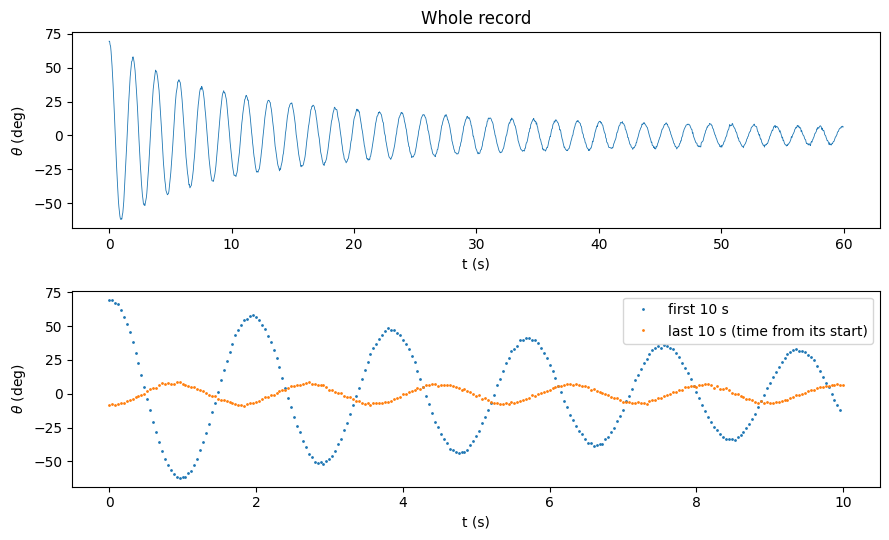

first 10 s: 5 upward crossings, 4 full periods; period estimate 1.870 s
small-angle period T0 = 2*pi*sqrt(L/g) with the local g: 1.794 s


In [2]:
fig, ax = plt.subplots(2, 1, figsize=(9, 5.5))
ax[0].plot(t, theta_deg, lw=0.6)
ax[0].set(xlabel="t (s)", ylabel=r"$\theta$ (deg)", title="Whole record")
m1, m2 = t < 10, t >= t[-1] - 10                     # masks: first 10 s, last 10 s
ax[1].plot(t[m1], theta_deg[m1], ".", ms=2, label="first 10 s")
ax[1].plot(t[m2] - t[m2][0], theta_deg[m2], ".", ms=2, label="last 10 s (time from its start)")
ax[1].set(xlabel="t (s)", ylabel=r"$\theta$ (deg)"); ax[1].legend()
plt.tight_layout(); plt.show()

# Period: an upward crossing is a frame with theta < 0 followed by one with theta >= 0.
# (number of full periods) = (number of crossings) - 1, and the time between the first and last crossing spans them.
up10 = np.where((theta[:-1] < 0) & (theta[1:] >= 0) & (t[1:] < 10))[0]
P_rough = (t[up10[-1]] - t[up10[0]])/(len(up10) - 1)
T0_local = 2*np.pi*np.sqrt(L/g_local)
print(f"first 10 s: {len(up10)} upward crossings, {len(up10)-1} full periods; period estimate {P_rough:.3f} s")
print(f"small-angle period T0 = 2*pi*sqrt(L/g) with the local g: {T0_local:.3f} s")

**What it shows.**
- *Plots.* A decaying oscillation: about 70° at release, about 7° after 60 s. The last 10 s also look more sinusoidal than the first 10 s.
- *Period.* Five upward crossings (four full periods) in the first 10 s give $P \approx 1.87$ s. This is longer than
  $T_0 = 1.794$ s. That is a first hint that the small-angle formula is not good enough at 70°.
- *The model as two first-order equations.* With $\omega = \dot\theta$:
  $$\dot\theta = \omega, \qquad \dot\omega = -\gamma\,\omega - \frac{g}{L}\sin\theta .$$
- *Classification.*
  - **Nonlinear**, because of the $\sin\theta$ term.
  - **Autonomous**: time does not appear explicitly, and the parameters are constant.
  - **Deterministic**: there is no random term in the *equation*; the noise is in the measurement.
  - **Dissipative**: for $\gamma > 0$ energy is removed.
- *Expected behaviour.* A decaying oscillation whose period gets shorter as the amplitude falls (the nonlinearity), tending to
  $T_0$ at small amplitude. With $\gamma = 0$ the energy per unit mass,
  $E = \tfrac12 L^2\omega^2 + gL(1-\cos\theta)$, is conserved. Task 2 uses this to test the solvers.

## Task 2 — Our own solvers, and why we can trust them
**What and why.** Everything after this point depends on the ODE solver, so it has to be tested on problems where we know
the answer. We write the right-hand side `f` once and pass it to two fixed-step integrators (Euler and RK4) with the
same interface, so they are interchangeable. We test them in three ways: (2.1) energy conservation with no damping;
(2.2) the order of convergence against a high-accuracy reference; (2.3) the step-halving test for the step we will actually use.

**From the equation of motion to `f`.** The equation of motion is second order:
$$\ddot\theta = -\gamma\dot\theta - \frac{g}{L}\sin\theta .$$
Euler and RK4 only handle first-order equations of the form "rate of change = a formula in the current values". The standard trick is to
give the first derivative its own name, the angular velocity $\omega = \dot\theta$. Then $\ddot\theta = \dot\omega$, and the single
second-order equation becomes **two first-order equations**:
$$\dot\theta = \omega, \qquad \dot\omega = -\gamma\,\omega - \frac{g}{L}\sin\theta .$$
The first is just the definition of ω; the second is the equation of motion. Together, the pair $y = (\theta, \omega)$ is the *state*
of the pendulum: where it is and how fast it is moving. Knowing the state at one instant fixes everything that follows.

`f(y, ...)` answers one question: *given the current state, how fast are θ and ω changing right now?* It returns
$(\dot\theta, \dot\omega)$. A solver calls `f` again and again, and each time takes a small step in the direction it gives.

**Example.** At release, θ = 70° and ω = 0:
- $\dot\theta = 0$: the angle is not changing yet;
- $\dot\omega = -(9.814/0.8)\sin 70^\circ \approx -11.5$ rad s$^{-2}$: gravity starts to swing the bob back.

One Euler step of $h = 0.01$ s leaves θ at 70° and changes ω to −0.115 rad/s. The next call to `f` uses this new state, and so on.

Three design choices:
- **No `t` argument.** Time does not appear explicitly in the equation (the system is *autonomous*).
- **`g` and `gamma` are arguments**, so that `curve_fit` can change them in every call through `model_theta`.
- **`L` is an argument with a default** (the measured 0.800 m). It is fixed for this pendulum, so we never pass it, but the function no
  longer depends silently on a variable defined elsewhere, and it can be reused for a different length.

In [3]:
def f(y, g, gamma, L=L):
    """Right-hand side of the damped pendulum, written as two first-order ODEs.
    y = (theta, omega). Returns (dtheta/dt, domega/dt) = (omega, -gamma*omega - (g/L) sin theta).
    L defaults to the length set above (0.800 m). The default is fixed when the function is defined."""
    theta_now, omega_now = y
    dtheta_dt = omega_now                                          # definition of omega
    domega_dt = -gamma*omega_now - (g/L)*np.sin(theta_now)         # the equation of motion
    return np.array([dtheta_dt, domega_dt])

# check against the worked example: released from rest at 70 degrees
print("f at release:", f(np.array([np.radians(70), 0.0]), g_local, 0.0), "(rad/s, rad/s^2)")

f at release: [  0.         -11.52775164] (rad/s, rad/s^2)


In [4]:
def euler(f, y0, t_end, h, *params):
    """Explicit Euler: y_{n+1} = y_n + h f(y_n). Fixed step h from t = 0 to t_end.
    Extra arguments (*params, e.g. g and gamma) are passed straight to f.
    Returns (times, y): times = 0, h, ..., N h with N = round(t_end/h); y has shape (N+1, 2), columns theta and omega."""
    N = int(round(t_end/h))
    y = np.empty((N + 1, len(y0))); y[0] = y0
    for n in range(N):
        y[n+1] = y[n] + h*f(y[n], *params)            # step along the tangent at the start of the step
    return np.arange(N + 1)*h, y

def rk4(f, y0, t_end, h, *params):
    """Classical fourth-order Runge-Kutta, with the same arguments and return format as euler.
    Each step samples the slope four times (start, two midpoint estimates, end) and takes a weighted average."""
    N = int(round(t_end/h))
    y = np.empty((N + 1, len(y0))); y[0] = y0
    for n in range(N):
        k1 = f(y[n], *params)                         # slope at the start
        k2 = f(y[n] + h/2*k1, *params)                # slope at the midpoint, using k1
        k3 = f(y[n] + h/2*k2, *params)                # slope at the midpoint again, using k2
        k4 = f(y[n] + h*k3, *params)                  # slope at the end, using k3
        y[n+1] = y[n] + h/6*(k1 + 2*k2 + 2*k3 + k4)
    return np.arange(N + 1)*h, y

def reference_solution(f, y0, t_end, h, *params):
    """(Provided in the starter notebook.) High-accuracy solution from solve_ivp (DOP853, tolerances 1e-12)
    at the same times 0, h, ..., t_end as our solvers, so the errors can be compared point by point."""
    t_eval = np.arange(int(round(t_end/h)) + 1)*h
    sol = solve_ivp(lambda t, y: f(y, *params), (0, t_eval[-1]), y0, t_eval=t_eval,
                    method="DOP853", rtol=1e-12, atol=1e-12)
    return t_eval, sol.y.T

def energy(y, g, L=L):
    """Energy per unit mass, E = (1/2) L^2 omega^2 + g L (1 - cos theta), for each row of y = (theta, omega).
    Constant when gamma = 0, so it is a test of the solver. L defaults to 0.800 m, as in f."""
    return 0.5*L**2*y[:, 1]**2 + g*L*(1 - np.cos(y[:, 0]))

y70 = np.array([np.radians(70), 0.0])                 # released from rest at 70 degrees

**2.1 Energy test.** Undamped ($\gamma = 0$), released from rest at 70°, for 10 s, at two steps per method. We plot
the relative energy error $|E(t)-E(0)|/E(0)$ on a log scale, so that errors of very different sizes appear on one plot.

Euler h = 0.040 s: E(10 s)/E(0) = 5.254967, max relative error 4.3e+00
Euler h = 0.004 s: E(10 s)/E(0) = 1.438500, max relative error 4.4e-01
RK4   h = 0.040 s: E(10 s)/E(0) = 0.999983, max relative error 1.8e-05
RK4   h = 0.004 s: E(10 s)/E(0) = 1.000000, max relative error 2.6e-10


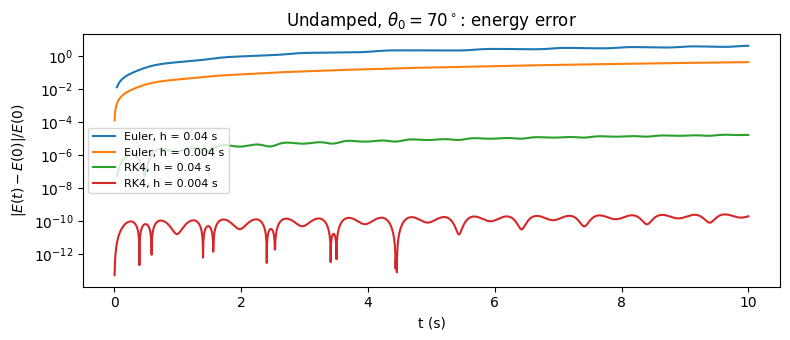

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for name, solver in (("Euler", euler), ("RK4", rk4)):
    for h_test in (0.04, 0.004):
        tt, yy = solver(f, y70, 10.0, h_test, g_local, 0.0)
        E = energy(yy, g_local); rel = np.abs(E - E[0])/E[0]
        ax.semilogy(tt[1:], rel[1:], label=f"{name}, h = {h_test:g} s")     # skip t = 0, where the error is exactly 0
        print(f"{name:5s} h = {h_test:5.3f} s: E(10 s)/E(0) = {E[-1]/E[0]:.6f}, max relative error {rel.max():.1e}")
ax.set(xlabel="t (s)", ylabel=r"$|E(t)-E(0)|/E(0)$", title=r"Undamped, $\theta_0=70^\circ$: energy error")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**What it shows.**
- *Euler's energy grows steadily.* After 10 s it is about 5.3 times the initial energy at $h = 0.04$ s, and still 1.4 times
  at $h = 0.004$ s.
- *Why.* Euler steps along the tangent at the start of each step. For a closed orbit in the $(\theta,\omega)$ plane, the
  tangent always points slightly *outward*, so every step adds a little energy. For the linearised pendulum the amplitude
  grows by a factor $\sqrt{1+(\Omega h)^2}$ per step, so the error is systematic, not random.
- *RK4.* Its energy error is $2\times10^{-5}$ at $h = 0.04$ s and $3\times10^{-10}$ at $h = 0.004$ s: tiny, and it falls
  steeply as $h$ is reduced. RK4 passes the test; Euler would be useless inside a fit.

**2.2 Order of convergence.** Compare each solver with `reference_solution` over $0 \le t \le 2$ s, using the maximum
error in $\theta$. Halve $h$ each time. The error ratio $e(h)/e(h/2)$ should approach $2^p$, where $p$ is the order of the method, so
$p = \log_2(\text{ratio})$.

   h       Euler error   ratio    p      RK4 error    ratio    p     (rad)
 0.0200   2.916e-01                  7.356e-07
 0.0100   1.441e-01     2.02  1.02   4.609e-08    15.96  4.00
 0.0050   7.125e-02     2.02  1.02   2.885e-09    15.98  4.00
 0.0025   3.539e-02     2.01  1.01   1.804e-10    15.99  4.00


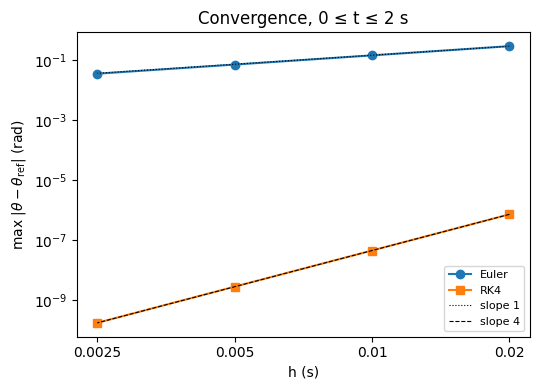

In [6]:
print("   h       Euler error   ratio    p      RK4 error    ratio    p     (rad)")
steps, errs, prev = (0.02, 0.01, 0.005, 0.0025), [], None
for h_test in steps:
    tr, yr = reference_solution(f, y70, 2.0, h_test, g_local, 0.0)
    _, yE = euler(f, y70, 2.0, h_test, g_local, 0.0)
    _, yR = rk4(f, y70, 2.0, h_test, g_local, 0.0)
    eE = np.abs(yE[:, 0] - yr[:, 0]).max(); eR = np.abs(yR[:, 0] - yr[:, 0]).max()
    errs.append((eE, eR))
    if prev:
        rE, rR = prev[0]/eE, prev[1]/eR
        print(f"{h_test:7.4f}   {eE:.3e}   {rE:6.2f}  {np.log2(rE):4.2f}   {eR:.3e}   {rR:6.2f}  {np.log2(rR):4.2f}")
    else:
        print(f"{h_test:7.4f}   {eE:.3e}                  {eR:.3e}")
    prev = (eE, eR)

errs = np.array(errs); hs = np.array(steps)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(hs, errs[:, 0], "o-", label="Euler"); ax.loglog(hs, errs[:, 1], "s-", label="RK4")
ax.loglog(hs, errs[0, 0]*(hs/hs[0])**1, "k:", lw=0.8, label=r"slope 1")
ax.loglog(hs, errs[0, 1]*(hs/hs[0])**4, "k--", lw=0.8, label=r"slope 4")
ax.set(xlabel="h (s)", ylabel=r"max $|\theta - \theta_{\rm ref}|$ (rad)", title="Convergence, 0 ≤ t ≤ 2 s"); ax.legend(fontsize=8)
ax.set_xticks(hs, [f"{x:g}" for x in hs]); ax.minorticks_off()
plt.tight_layout(); plt.show()

**What it shows.** The Euler ratios are 2.0 ($p = 1.0$) and the RK4 ratios are 16.0 ($p = 4.0$) for every halving down to
$h = 0.0025$ s. These are the theoretical orders, so both codes are implemented correctly. The RK4 error at
the smallest step ($\approx 2\times10^{-10}$ rad) is still far above the reference's $10^{-12}$ tolerance, so the
reference is good enough to measure it.

**2.3 Choice of step.** The step must divide the frame interval exactly, so that the model is evaluated at the frame times.
Use the step-halving test over the full 60 s: if halving $h$ changes $\theta$ by much less than the measurement uncertainty
$\sigma = 0.5^\circ$ (here: below $\sigma/10$), the step is small enough.

In [7]:
for h_test in (dt, dt/2, dt/4):
    _, ya = rk4(f, y70, 60.0, h_test, g_local, 0.0)
    _, yb = rk4(f, y70, 60.0, h_test/2, g_local, 0.0)
    diff = np.degrees(np.abs(ya[:, 0] - yb[::2, 0]).max())       # yb[::2]: every other step = the same times as ya
    print(f"h = dt/{round(dt/h_test)} = {h_test:.5f} s: max |theta_h - theta_h/2| = {diff:.1e} deg = {diff/0.5:.1e} sigma")
h = dt/4
print(f"chosen h = dt/4 = {h:g} s")

h = dt/1 = 0.04000 s: max |theta_h - theta_h/2| = 5.5e-02 deg = 1.1e-01 sigma
h = dt/2 = 0.02000 s: max |theta_h - theta_h/2| = 9.6e-04 deg = 1.9e-03 sigma


h = dt/4 = 0.01000 s: max |theta_h - theta_h/2| = 2.9e-05 deg = 5.9e-05 sigma
chosen h = dt/4 = 0.01 s


**What it shows.** Halving $h = 0.04$ s changes $\theta$ by 0.11σ, so the frame interval itself *just fails* the
$\sigma/10$ criterion. $h = 0.02$ s (0.002σ) passes, and $h = 0.01$ s ($6\times10^{-5}$σ) passes with a large margin. We use
$h = 0.01$ s: it divides $\Delta t$ exactly, the solver error is negligible compared with the noise, and a whole-record fit still takes only seconds.

## Task 3 — Measure $g$ by fitting
**What and why.** Two models, from simple to realistic. (3.1) The small-angle analytic solution: quick, but we expect it to fail
at 70°. (3.2) Our RK4 model of the full nonlinear equation inside `curve_fit`. Both fits are weighted by the frame
uncertainty with `absolute_sigma=True`, so the quoted parameter uncertainties come from σ itself. We then judge each fit by
$\chi^2/\nu$ and the residuals (3.3).

In [8]:
def chi2_nu(data, model_values, s, n_par):
    """Reduced chi-squared: sum(((data - model)/s)^2) / (N - n_par), with N data points and n_par fitted parameters.
    About 1 if the model is right and s is the true noise; much greater than 1 means the misfit is larger than the noise."""
    return np.sum(((data - model_values)/s)**2)/(len(data) - n_par)

def small_angle(t, A, beta, Omega, phi):
    """Small-angle, lightly damped solution: theta = A exp(-beta t) cos(Omega t + phi). Then g = Omega^2 L."""
    return A*np.exp(-beta*t)*np.cos(Omega*t + phi)

# 3.1: start Omega from the Task 1 period, the amplitude from the release angle, beta small
pa, Ca = curve_fit(small_angle, t, theta, p0=(np.radians(70), 0.02, 2*np.pi/P_rough, 0.0),
                   sigma=s_all, absolute_sigma=True)
ea = np.sqrt(np.diag(Ca))
g_a = pa[2]**2*L; eg_a = 2*pa[2]*L*ea[2]               # error propagation: dg = 2 Omega L dOmega
res_a = (theta - small_angle(t, *pa))/sigma             # residuals in units of sigma
print(f"3.1 small-angle: Omega = {pa[2]:.4f} rad/s, beta = {pa[1]:.4f} 1/s, g = Omega^2 L = {g_a:.4f} +- {eg_a:.4f} m/s^2, "
      f"chi2/nu = {chi2_nu(theta, small_angle(t, *pa), sigma, 4):.1f}")

3.1 small-angle: Omega = 3.4509 rad/s, beta = 0.0533 1/s, g = Omega^2 L = 9.5270 +- 0.0005 m/s^2, chi2/nu = 116.1


**What it shows.** $g = 9.527$ m s$^{-2}$ with $\chi^2/\nu = 116$. The fit is far worse than the noise allows, and $g$ is
almost 0.3 m s$^{-2}$ too low. A single fixed $\Omega$ cannot follow a period that changes with amplitude, so it settles on a
compromise. Its formal uncertainty (±0.0005) means nothing when the model is this wrong. **The small-angle model fails at 70°.**

**3.2 The numerical model.** `model_theta` (from the starter notebook) runs our RK4 from rest at $\theta_0$ and returns
$\theta$ at the frame times. `curve_fit` adjusts $(\theta_0, g, \gamma)$ to minimise $\chi^2$. First test it on the first
10 s (fast, and a check that it converges from our starting guesses), then fit the whole record, starting from the 10-s result.

In [9]:
def model_theta(t_data, theta0, g, gamma):
    """(Provided in the starter notebook.) theta (rad) at the times t_data, for the pendulum released from rest at theta0,
    from our RK4 with step h. Requires dt/h to be a whole number, so that every frame time is a solver step."""
    y0 = np.array([theta0, 0.0])                                   # theta(0) = theta0, omega(0) = 0
    times, y = rk4(f, y0, t_data.max(), h, g, gamma)               # integrate from t = 0 to the last requested time
    idx = np.rint(t_data/h).astype(int)                            # the solver step at each requested time
    return y[idx, 0]

m = t < 10
p10, C10 = curve_fit(model_theta, t[m], theta[m], p0=(np.radians(70), 9.8, 0.05), sigma=s_all[m], absolute_sigma=True)
print(f"3.2 test on first 10 s: theta0 = {np.degrees(p10[0]):.2f} deg, g = {p10[1]:.4f}, gamma = {p10[2]:.4f}")

t_start = time.time()
pb, Cb = curve_fit(model_theta, t, theta, p0=p10, sigma=s_all, absolute_sigma=True)
eb = np.sqrt(np.diag(Cb)); res_b = (theta - model_theta(t, *pb))/sigma
print(f"3.2 whole record ({time.time()-t_start:.0f} s): theta0 = {np.degrees(pb[0]):.2f} +- {np.degrees(eb[0]):.2f} deg, "
      f"g = {pb[1]:.4f} +- {eb[1]:.4f} m/s^2, gamma = {pb[2]:.4f} +- {eb[2]:.4f} 1/s, "
      f"chi2/nu = {chi2_nu(theta, model_theta(t, *pb), sigma, 3):.2f}")
for ref, name in ((g_local, "local (WGS84)"), (9.81, "9.81"), (9.80665, "standard 9.80665")):
    print(f"  (g - {name})/sigma_g = {(pb[1]-ref)/eb[1]:+.0f}")

3.2 test on first 10 s: theta0 = 67.99 deg, g = 9.8216, gamma = 0.1644


3.2 whole record (4 s): theta0 = 61.37 +- 0.04 deg, g = 9.8344 +- 0.0007 m/s^2, gamma = 0.1069 +- 0.0001 1/s, chi2/nu = 26.90
  (g - local (WGS84))/sigma_g = +30
  (g - 9.81)/sigma_g = +36
  (g - standard 9.80665)/sigma_g = +41


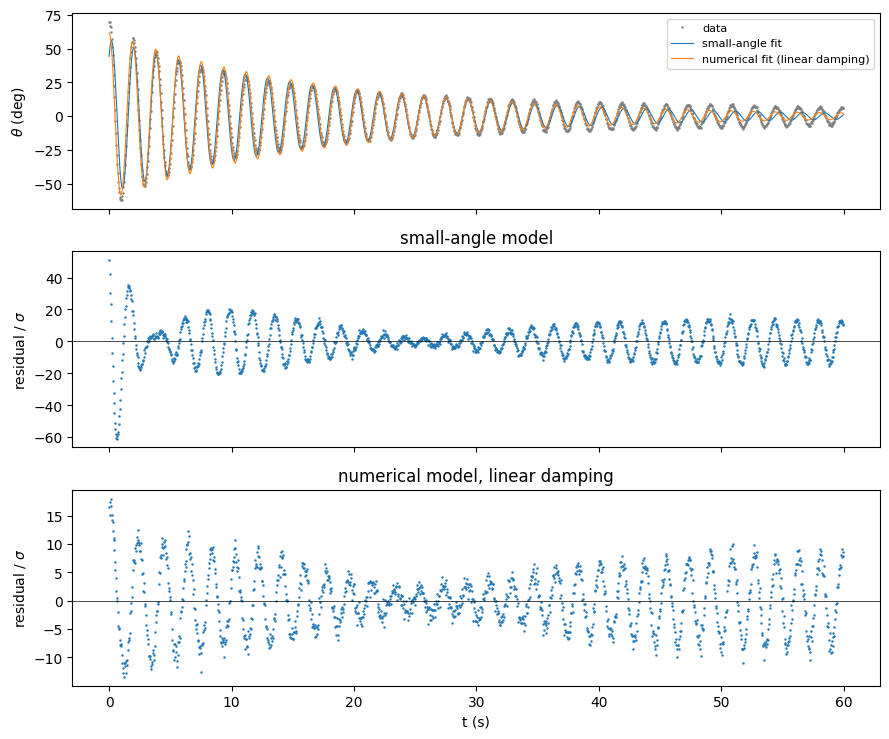

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
ax[0].plot(t, theta_deg, ".", ms=1.5, c="0.5", label="data")
ax[0].plot(t, np.degrees(small_angle(t, *pa)), lw=0.8, label="small-angle fit")
ax[0].plot(t, np.degrees(model_theta(t, *pb)), lw=0.8, label="numerical fit (linear damping)")
ax[0].set(ylabel=r"$\theta$ (deg)"); ax[0].legend(loc="upper right", fontsize=8)
ax[1].plot(t, res_a, ".", ms=1.5); ax[1].set(ylabel=r"residual / $\sigma$", title="small-angle model")
ax[2].plot(t, res_b, ".", ms=1.5); ax[2].set(ylabel=r"residual / $\sigma$", xlabel="t (s)", title="numerical model, linear damping")
for a in ax[1:]: a.axhline(0, c="k", lw=0.5)
plt.tight_layout(); plt.show()

**What it shows (3.2 and 3.3).**
- *Fit.* The 10-s test converges ($\theta_0 = 68.0^\circ$, $g = 9.822$). The whole-record fit gives
  $\theta_0 = 61.37 \pm 0.04^\circ$, $g = 9.8344 \pm 0.0007$ m s$^{-2}$ and $\gamma = 0.1069 \pm 0.0001$ s$^{-1}$, with $\chi^2/\nu = 26.9$.
- *Better, but not right.* This is much better than the small-angle fit, but it is still not a good fit:
  - $\chi^2/\nu$ should be about 1;
  - the residuals are many σ, and they are *structured*: an oscillating pattern, largest at the start, not random scatter.
- *Comparison with the local value.* $g$ is $+30\sigma$ from the local 9.8141 m s$^{-2}$ (and further from 9.81 or 9.80665).
- *The release angle.* The fitted $\theta_0 = 61^\circ$ disagrees with the data themselves: the first frame reads 69.6°.

**Conclusion.** The quoted uncertainty only reflects the noise. The misfit says the *model* is still incomplete, so neither
this value of $g$ nor its uncertainty can be trusted yet. Tasks 4–6 look for what is missing.

## Task 4 — Period against amplitude
**What and why.** Task 1 hinted that the period depends on amplitude. Here we measure the period of every cycle and compare it with
theory. (4.1) Upward zero crossings come from our own bisection root finder, applied to a cubic spline through the
frames: the spline gives a smooth function between frames, and bisection is guaranteed to converge once a sign change is
bracketed. We check every root against SciPy's `brentq`. (4.2) The amplitude of each period comes from the frames
between its two crossings. (4.3) The exact undamped period is $T = 4\sqrt{L/g}\,K(k)$ with $k = \sin(\theta_a/2)$.
We use `ellipk`, which takes $m = k^2$, and check one value with our own Simpson rule.

In [11]:
def bisection(func, a, b, tol=1e-6, maxit=200):
    """Root of func in [a, b] by repeated halving. Requires a sign change: func(a)*func(b) <= 0.
    Stops when the bracket is narrower than tol. Returns (root, number of iterations)."""
    fa = func(a)
    for n in range(1, maxit + 1):
        mid = 0.5*(a + b); fm = func(mid)
        if fa*fm <= 0: b = mid                     # the sign change is in the left half
        else: a, fa = mid, fm                      # ... otherwise in the right half
        if b - a < tol: return 0.5*(a + b), n
    raise RuntimeError("bisection did not converge")

S = CubicSpline(t, theta)                          # smooth interpolant through all frames: S(t) can be evaluated anywhere
raw = np.where((theta[:-1] < 0) & (theta[1:] >= 0))[0]                  # frames just before each upward sign change
keep = [raw[0]] + [b for a, b in zip(raw[:-1], raw[1:]) if b - a > 5]  # guard: drop noise-induced double crossings
tz, iters = [], []
for i in keep:
    r, n = bisection(S, t[i], t[i+1]); tz.append(r); iters.append(n)    # bracket = the two frames either side
tz = np.array(tz); P = np.diff(tz)                                        # one period between successive crossings
check = np.array([brentq(S, t[i], t[i+1]) for i in keep])
print(f"upward sign changes {len(raw)}, kept {len(keep)} crossings -> {len(P)} periods")
print(f"bisection iterations per crossing: {min(iters)}-{max(iters)}; largest difference from brentq: {np.abs(check - tz).max():.1e} s")

# 4.2 amplitude of each period: half the peak-to-peak range of the frames between its two crossings
amp = np.array([0.5*(theta[(t > a) & (t < b)].max() + abs(theta[(t > a) & (t < b)].min())) for a, b in zip(tz[:-1], tz[1:])])
print(f"first period {P[0]:.4f} s at {np.degrees(amp[0]):.1f} deg; last {P[-1]:.4f} s at {np.degrees(amp[-1]):.1f} deg")

upward sign changes 33, kept 33 crossings -> 32 periods
bisection iterations per crossing: 16-16; largest difference from brentq: 3.0e-07 s
first period 1.8988 s at 54.9 deg; last 1.7938 s at 7.1 deg


**What it shows (4.1–4.2).** There are 33 upward crossings, giving 32 periods. The closest pair is 44 frames apart, so
the guard against noise-induced double crossings did not need to remove any. Each crossing takes 16 bisection iterations
(a 0.04 s bracket halved down to $10^{-6}$ s: $0.04/2^{16} \approx 6\times10^{-7}$ s). Every root agrees with `brentq` to
$3\times10^{-7}$ s, so the root finder is correct. The period falls from 1.899 s (first cycle, amplitude 54.9°) to 1.794 s
(last cycle, 7.1°).

Simpson,  4 intervals: K = 1.7312142958;  ellipk(k^2) = 1.7312451757;  ellipk(k) = 1.9220
Simpson,  8 intervals: K = 1.7312451735;  ellipk(k^2) = 1.7312451757;  ellipk(k) = 1.9220
Simpson, 16 intervals: K = 1.7312451757;  ellipk(k^2) = 1.7312451757;  ellipk(k) = 1.9220


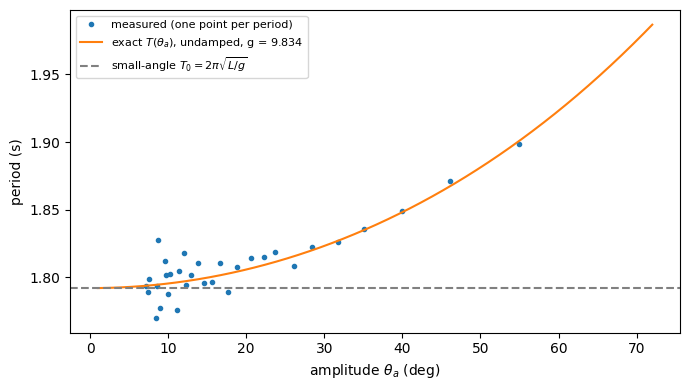

T0 = 1.7921 s; measured periods 1.7699-1.8988 s


In [12]:
def simpson(values, spacing):
    """Composite Simpson's rule for samples on an evenly spaced grid. Needs an even number of intervals
    (an odd number of samples). Weights: spacing/3 * (1, 4, 2, 4, ..., 2, 4, 1)."""
    if (len(values) - 1) % 2:
        raise ValueError("Simpson's rule needs an even number of intervals")
    return spacing/3*(values[0] + 4*values[1:-1:2].sum() + 2*values[2:-1:2].sum() + values[-1])

def K(k, n):
    """Complete elliptic integral of the first kind, K(k) = integral from 0 to pi/2 of dpsi / sqrt(1 - k^2 sin^2 psi),
    by our Simpson rule with n intervals. (scipy's ellipk takes m = k^2, not k.)"""
    psi = np.linspace(0, np.pi/2, n + 1)
    return simpson(1/np.sqrt(1 - k**2*np.sin(psi)**2), psi[1] - psi[0])

k70 = np.sin(np.radians(70)/2)
for n_K in (4, 8, 16):
    print(f"Simpson, {n_K:2d} intervals: K = {K(k70, n_K):.10f};  ellipk(k^2) = {ellipk(k70**2):.10f};  ellipk(k) = {ellipk(k70):.4f}")

g_fit = pb[1]                                                     # our Task 3 value
T0 = 2*np.pi*np.sqrt(L/g_fit)
a_grid = np.radians(np.linspace(1, 72, 200))
T_exact = 4*np.sqrt(L/g_fit)*ellipk(np.sin(a_grid/2)**2)        # exact undamped period at each amplitude
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.degrees(amp), P, "o", ms=3, label="measured (one point per period)")
ax.plot(np.degrees(a_grid), T_exact, label=rf"exact $T(\theta_a)$, undamped, g = {g_fit:.3f}")
ax.axhline(T0, ls="--", c="gray", label=r"small-angle $T_0=2\pi\sqrt{L/g}$")
ax.set(xlabel=r"amplitude $\theta_a$ (deg)", ylabel="period (s)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"T0 = {T0:.4f} s; measured periods {P.min():.4f}-{P.max():.4f} s")

**What it shows (4.3–4.4).**
- *Check of $K$.* At 70°, $K = 1.73125$. Simpson agrees with `ellipk(k**2)` to $3\times10^{-5}$ with 4 intervals, $2\times10^{-9}$ with 8,
  and to all printed digits with 16. Passing $k$ instead of $k^2$ would give 1.922, an 11% error: easy to spot once you check.
- *The pendulum is not linear.* The measured period rises from about 1.79 s at small amplitudes to 1.90 s at 55°, and it
  follows the exact curve $T(\theta_a)$, not the constant $T_0 = 1.792$ s.
- *Scatter at small amplitude.* The small-amplitude periods scatter more (1.77–1.83 s). The timing error of a crossing is
  about σ divided by the angular speed at the crossing, and that speed is proportional to the amplitude: the slower the
  swing, the less sharply each crossing is defined.

## Task 5 — Angular velocity and extrapolation
**What and why.** (5.1) Estimate $\omega$ directly from the data by central differences, $\omega_n \approx (\theta_{n+1}-\theta_{n-1})/2\Delta t$,
and compare with $\omega$ from the fitted model. If the model were right, the difference would be pure noise, of known
size: each difference combines two independent errors of σ, so its noise is $\sqrt2\,\sigma/(2\Delta t) = \sigma/(\sqrt2\,\Delta t)$
(Lecture 4). (5.2) Run the fitted model forward to find when the amplitude falls below 1°.

rms(central difference - model) = 12.1 deg/s; expected from noise sigma/(sqrt2 dt) = 8.8 deg/s


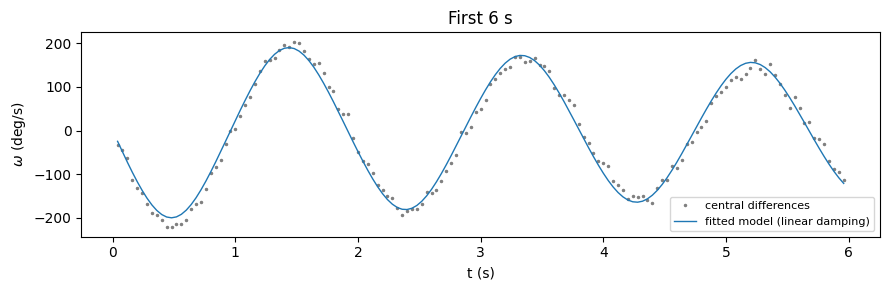

In [13]:
omega_cd = (theta[2:] - theta[:-2])/(2*dt)                       # central differences: frames 1 ... N-2
_, y_fit = rk4(f, np.array([pb[0], 0.0]), t[-1], h, pb[1], pb[2])
omega_model = y_fit[np.rint(t/h).astype(int), 1]                 # model omega at the frame times
rms = np.sqrt(np.mean((omega_cd - omega_model[1:-1])**2))
expected = np.sqrt(2)*sigma/(2*dt)                               # = sigma/(sqrt2 dt)
print(f"rms(central difference - model) = {np.degrees(rms):.1f} deg/s; expected from noise sigma/(sqrt2 dt) = {np.degrees(expected):.1f} deg/s")

fig, ax = plt.subplots(figsize=(9, 3))
w = t[1:-1] < 6
ax.plot(t[1:-1][w], np.degrees(omega_cd[w]), ".", ms=3, c="0.5", label="central differences")
ax.plot(t[1:-1][w], np.degrees(omega_model[1:-1][w]), lw=1, label="fitted model (linear damping)")
ax.set(xlabel="t (s)", ylabel=r"$\omega$ (deg/s)", title="First 6 s"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What it shows.** The rms difference is 12.1 °/s, against 8.8 °/s expected from the noise alone. The truncation error
of the central difference here is below 1 °/s, so it cannot explain the excess. The extra difference comes from the *model*: it is a
third independent sign, after $\chi^2/\nu$ and the residuals, that linear damping does not describe this pendulum.

In [14]:
def time_below_1deg(theta0, g, gamma, c=None, t_end=1200.0, step=0.01):
    """First time (s) at which the amplitude falls below 1 degree, running the model from rest at theta0.
    The amplitude at any instant comes from the energy: E = g L (1 - cos theta_a), so theta_a = arccos(1 - E/(g L)).
    This gives a smooth amplitude without having to find the peaks. With c given, uses the drag model (Task 6)."""
    if c is None:
        _, y = rk4(f, np.array([theta0, 0.0]), t_end, step, g, gamma)
    else:
        _, y = rk4(f_drag, np.array([theta0, 0.0]), t_end, step, g, gamma, c)
    a = np.degrees(np.arccos(1 - energy(y, g)/(g*L)))
    i = np.argmax(a < 1.0)                                         # first index below 1 degree (0 if none)
    return i*step if a[i] < 1.0 else np.nan

print(f"amplitude falls below 1 deg at t = {time_below_1deg(*pb):.0f} s (linear-damping model)")

amplitude falls below 1 deg at t = 76 s (linear-damping model)


**What it shows.** The linear-damping model predicts that the amplitude falls below 1° at about **76 s**, 16 s
after the record ends. We do **not** trust it far. The prediction assumes that the model and its constant
parameters hold outside the record, at amplitudes smaller than any we fitted. Tasks 3 and 5 already show that the model is
incomplete. The error is likely to grow with the length of the extrapolation, and its sign is unknown without knowing what is missing.

## Task 6 — Extension: what is the model missing?
**Why this question.** Three results point the same way. In Task 3, $\chi^2/\nu = 27$, the residuals are structured, and the fitted release
angle is 61° when the first frame reads 70°. In Task 5, the velocity scatter is 12.1 °/s against 8.8 °/s from noise.
So the obvious next question is: *what is the model missing, and does adding it change $g$?*

**Plan.**
1. Show that the residuals are not random, by averaging them in 2-s blocks.
2. Test whether the damping rate depends on amplitude, by fitting $\gamma$ separately to the first and second halves of the record.
3. If it does, add the standard amplitude-dependent term, quadratic air drag $c\,\dot\theta|\dot\theta|$, and refit.
4. Check whether every earlier symptom goes away, and whether the new uncertainty is believable.

In [15]:
nb = 50                                                            # 50 frames = 2-s blocks
blocks = res_b[:len(res_b)//nb*nb].reshape(-1, nb).mean(1)
print(f"2-s block means of the residuals: rms {np.sqrt(np.mean(blocks**2)):.2f} (expected 1/sqrt({nb}) = {1/np.sqrt(nb):.2f} if random)")

half = len(t)//2
p1st, C1st = curve_fit(model_theta, t[:half], theta[:half], p0=pb, sigma=s_all[:half], absolute_sigma=True)

def model_free_start(t_data, theta_s, omega_s, g, gamma):
    """Like model_theta, but starting at the first requested time with a free angle AND angular velocity,
    so a later section of the record can be fitted on its own (the pendulum is not at rest there)."""
    _, y = rk4(f, np.array([theta_s, omega_s]), t_data.max() - t_data.min(), h, g, gamma)
    return y[np.rint((t_data - t_data.min())/h).astype(int), 0]

p2nd, C2nd = curve_fit(model_free_start, t[half:], theta[half:], p0=(theta[half], 0.0, pb[1], pb[2]),
                       sigma=s_all[half:], absolute_sigma=True)
print(f"gamma, first 30 s: {p1st[2]:.4f} +- {np.sqrt(C1st[2,2]):.4f} 1/s; last 30 s: {p2nd[3]:.4f} +- {np.sqrt(C2nd[3,3]):.4f} 1/s")

2-s block means of the residuals: rms 0.39 (expected 1/sqrt(50) = 0.14 if random)


gamma, first 30 s: 0.1254 +- 0.0002 1/s; last 30 s: 0.0491 +- 0.0007 1/s


**What it shows.** If the residuals were pure noise, the 2-s block means would scatter by $1/\sqrt{50} = 0.14$; instead their rms
is 0.39, so the residuals are systematic. The damping rate fitted to the first 30 s ($0.125$ s$^{-1}$) is **2.5 times** that
fitted to the last 30 s ($0.049$ s$^{-1}$), a difference of over 100 standard errors. Linear damping assumes a single
$\gamma$, but the damping is clearly stronger at large amplitude, where the bob moves fastest. That is the signature of air drag, which grows
like the square of the speed: $\ddot\theta + \gamma\dot\theta + c\,\dot\theta|\dot\theta| + (g/L)\sin\theta = 0$.
(The $|\dot\theta|$ makes the drag always oppose the motion.)

with quadratic drag: theta0 = 69.97 +- 0.07 deg, g = 9.8137 +- 0.0005 m/s^2, gamma = 0.0205 +- 0.0004 1/s, c = 0.0597 +- 0.0003 1/rad, chi2/nu = 1.020
(g - g_local)/sigma_g = -0.7
2-s block means now: rms 0.14
central difference against this model: rms 8.9 deg/s (expected 8.8)


amplitude below 1 deg, with quadratic drag: 189 s


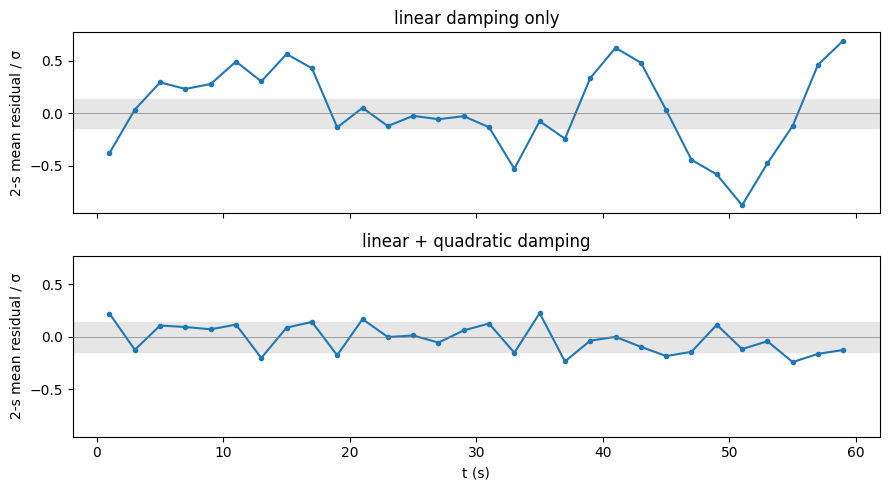

In [16]:
def f_drag(y, g, gamma, c, L=L):
    """Right-hand side with linear AND quadratic damping: domega/dt = -gamma*omega - c*omega*|omega| - (g/L) sin theta.
    The same as f, plus one term; the |omega| makes the drag always oppose the motion."""
    return np.array([y[1], -gamma*y[1] - c*y[1]*abs(y[1]) - (g/L)*np.sin(y[0])])

def model_drag(t_data, theta0, g, gamma, c):
    """model_theta for the drag model: theta at t_data, released from rest at theta0."""
    _, y = rk4(f_drag, np.array([theta0, 0.0]), t_data.max(), h, g, gamma, c)
    return y[np.rint(t_data/h).astype(int), 0]

pd_, Cd = curve_fit(model_drag, t, theta, p0=(pb[0], pb[1], 0.02, 0.05), sigma=s_all, absolute_sigma=True)
ed = np.sqrt(np.diag(Cd)); res_d = (theta - model_drag(t, *pd_))/sigma
print(f"with quadratic drag: theta0 = {np.degrees(pd_[0]):.2f} +- {np.degrees(ed[0]):.2f} deg, g = {pd_[1]:.4f} +- {ed[1]:.4f} m/s^2, "
      f"gamma = {pd_[2]:.4f} +- {ed[2]:.4f} 1/s, c = {pd_[3]:.4f} +- {ed[3]:.4f} 1/rad, chi2/nu = {chi2_nu(theta, model_drag(t, *pd_), sigma, 4):.3f}")
print(f"(g - g_local)/sigma_g = {(pd_[1]-g_local)/ed[1]:.1f}")

blocks_d = res_d[:len(res_d)//nb*nb].reshape(-1, nb).mean(1)
print(f"2-s block means now: rms {np.sqrt(np.mean(blocks_d**2)):.2f}")
_, yd = rk4(f_drag, np.array([pd_[0], 0.0]), t[-1], h, *pd_[1:]); om_d = yd[np.rint(t/h).astype(int), 1]
print(f"central difference against this model: rms {np.degrees(np.sqrt(np.mean((omega_cd - om_d[1:-1])**2))):.1f} deg/s (expected {np.degrees(expected):.1f})")
print(f"amplitude below 1 deg, with quadratic drag: {time_below_1deg(*pd_[:3], c=pd_[3]):.0f} s")

fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True, sharey=True)
ax[0].plot(t[:len(blocks)*nb:nb] + 1, blocks, "o-", ms=3); ax[0].set(ylabel="2-s mean residual / σ", title="linear damping only")
ax[1].plot(t[:len(blocks_d)*nb:nb] + 1, blocks_d, "o-", ms=3); ax[1].set(ylabel="2-s mean residual / σ", xlabel="t (s)", title="linear + quadratic damping")
for a in ax:
    a.axhline(0, c="gray", lw=0.5)
    a.axhspan(-1/np.sqrt(nb), 1/np.sqrt(nb), color="0.9", zorder=0)   # band expected from noise alone
plt.tight_layout(); plt.show()

**What it shows.** Adding one parameter, $c$, removes every symptom:
- $\chi^2/\nu = 1.02$, consistent with noise alone.
- The block means fall to 0.14, exactly the value expected if the residuals are random (inside the grey band in the figure).
- The fitted release angle is now $69.97 \pm 0.07^\circ$, consistent with the first frame.
- The velocity scatter is 8.9 °/s against 8.8 °/s expected.
- $g = 9.8137 \pm 0.0005$ m s$^{-2}$, which agrees with the local 9.8141 to within $0.7\sigma$.

The linear damping has fallen from 0.107 to $0.0205 \pm 0.0004$ s$^{-1}$: in the old model, $\gamma$ had been absorbing the drag. The
predicted time to fall below 1° changes from 76 s to **189 s**, because quadratic drag fades as the swing slows. This shows how far
an extrapolation from an incomplete model can be wrong.

**Is the new uncertainty believable?** $\chi^2/\nu \approx 1$ is necessary but not sufficient. To test the quoted
$\pm 0.0005$, we simulate 40 records from the best-fit drag model with fresh noise, fit each one, and look at the *pulls*
$(g_{\rm fit} - g_{\rm true})/\sigma_g$. If the uncertainties are right, the pulls have mean 0 and standard deviation 1.

In [17]:
rng = np.random.default_rng(7)                                     # fixed seed: reproducible
truth = model_drag(t, *pd_)
pulls = []
for _ in range(40):
    ps, Cs = curve_fit(model_drag, t, truth + sigma*rng.standard_normal(len(t)), p0=pd_, sigma=s_all, absolute_sigma=True)
    pulls.append((ps[1] - pd_[1])/np.sqrt(Cs[1, 1]))
pulls = np.array(pulls)
print(f"pulls of g over 40 simulated records: mean {pulls.mean():.2f}, standard deviation {pulls.std(ddof=1):.2f} (expect 0 and 1)")

pulls of g over 40 simulated records: mean -0.04, standard deviation 1.06 (expect 0 and 1)


**What it shows.** The pulls have mean −0.04 and standard deviation 1.06. With 40 records these are uncertain by about ±0.16 and ±0.11, so
both agree with 0 and 1. The fitting method is unbiased and its quoted uncertainty is believable.

## Other extension routes
These were not needed above. Each would have been a valid extension *if* it was motivated by the Task 1–5 results and ended in a
conclusion.

**Moving-window velocities.** Central differences use only two frames, so they are noisy. A Savitzky–Golay filter fits a
quadratic to a window of frames and differentiates it (Week 3). Wider windows average more noise but smooth the true signal near the
turning points. Here the comparison is with the linear-damping model, so the floor is set by that model's misfit.

In [18]:
from scipy.signal import savgol_filter
for w in (5, 9, 15):
    om_w = savgol_filter(theta, w, 2, deriv=1, delta=dt)           # local quadratic over w frames, first derivative
    r = np.degrees(np.sqrt(np.mean((om_w[w:-w] - omega_model[w:-w])**2)))
    print(f"window {w:2d} frames ({w*dt:.2f} s): rms difference from the model {r:.1f} deg/s")

window  5 frames (0.20 s): rms difference from the model 9.3 deg/s
window  9 frames (0.36 s): rms difference from the model 8.8 deg/s
window 15 frames (0.60 s): rms difference from the model 10.3 deg/s


**What it shows.** The rms difference is 9.3, 8.8 and 10.3 °/s for windows of 5, 9 and 15 frames: a minimum near 9 frames. Small
windows are dominated by noise and large windows by smoothing bias. A student taking this route should show the trade-off, not pick one window.

**Energy balance.** A check of the integration and of the energy bookkeeping: the energy lost over 60 s should equal
the work done by damping, $\int_0^{60}\gamma L^2\omega^2\,dt$ (per unit mass), evaluated with our Simpson rule.

In [19]:
_, y60 = rk4(f, np.array([pb[0], 0.0]), 60.0, h, pb[1], pb[2])
E60 = energy(y60, pb[1])
dissipated = simpson(pb[2]*L**2*y60[:, 1]**2, h)
print(f"E(0) - E(60 s) = {E60[0]-E60[-1]:.4f} J/kg;  integral of gamma L^2 omega^2 = {dissipated:.4f} J/kg ({len(y60)-1} intervals)")

E(0) - E(60 s) = 4.0907 J/kg;  integral of gamma L^2 omega^2 = 4.0907 J/kg (6000 intervals)


**What it shows.** Both sides are 4.0907 J/kg, agreeing to four figures. This confirms the solver and the bookkeeping, but
it says nothing about whether the *physics* is right: it holds for any model we integrate correctly.

## Interpretive statement
*(About 230 words, one figure: the Task 3 plot of the data, both fits and their residuals.)*

My best estimate is $g = 9.8137 \pm 0.0005$ m s$^{-2}$. It comes from fitting an RK4 model with linear *and* quadratic damping to all
1500 frames ($\chi^2/\nu = 1.02$). It agrees with the local value at Lancaster, 9.8141 m s$^{-2}$ (WGS84 normal gravity at 54.0° N, minus
a 50 m free-air correction), within $0.7\sigma$.

I trust the solver because it passed three tests. RK4 conserves the undamped energy to $2\times10^{-5}$ at $h = 0.04$ s, while Euler's
energy grows five-fold. The error falls by a factor of 16 per halving of $h$ (order 4). Halving my step of 0.01 s changes θ by
$6\times10^{-5}\sigma$.

The pendulum is not linear. The small-angle fit fails badly ($\chi^2/\nu = 116$, $g = 9.53$). The measured period falls from 1.90 s at
55° to 1.79 s at 7°, following the exact elliptic-integral period, not the constant $T_0$.

The model the brief asked for (linear damping) gave $g = 9.8344 \pm 0.0007$, 30σ from the local value, with $\chi^2/\nu = 27$ and
residuals largest at the start. Three things pointed to missing physics: the fitted release angle was 61° rather than ~70°; γ fitted
to the first 30 s was 2.5 times that for the last 30 s; and the velocity scatter was 12.1 °/s against the 8.8 °/s expected from noise
alone. Adding air drag ($c\,\dot\theta|\dot\theta|$) removed all three: θ₀ = 70.0°, random block-averaged residuals, and 8.9 °/s.

A pull study on 40 simulated records gave mean −0.04 and width 1.06, so the quoted uncertainty is believable. The amplitude now
falls below 1° at 189 s, not 76 s. Next, I would measure the drag directly, for example by repeating with a different bob shape.

<hr style="border:none;border-top:1px solid #BEC0C2;margin-top:32px;">
<div style="color:#555656;font-size:12px;margin-top:8px;font-family:Arial, Helvetica, sans-serif;">
PHYS7101 &mdash; Numerical Methods and Data Analysis
</div>